<a href="https://colab.research.google.com/github/Koroush-Mashayekh/diabetes-risk-prediction/blob/main/notebooks/02_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

URL = "https://raw.githubusercontent.com/Koroush-Mashayekh/diabetes-risk-prediction/main/data/diabetes.csv"
df = pd.read_csv(URL)

print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 1. Train/test split
80% of the data is used for training and 20% is held out as a final test set.
The split is **stratified** to keep the same class ratio (65/35) in both sets,
and `random_state=42` makes the split reproducible.

**Result:** 614 training samples and 154 test samples.
The diabetes ratio is almost identical in both sets (34.9% vs. 35.1%), confirming the stratified split.
The test set will only be used for the final evaluation.

In [2]:
from sklearn.model_selection import train_test_split

X= df.drop(columns = "Outcome")
y= df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = y, random_state = 42)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Diabetes ratio in train:", round(y_train.mean(), 3))
print("Diabetes ratio in test:", round(y_test.mean(), 3))

Train: (614, 8) Test: (154, 8)
Diabetes ratio in train: 0.349
Diabetes ratio in test: 0.351


## 2. Baseline model
A naive model that always predicts the most frequent class ("no diabetes").
Any useful model must clearly outperform this baseline.

**Result:** The baseline reaches **64.9% accuracy** but a **recall of 0.0**: it does not detect a single
diabetic patient. Its ROC-AUC of 0.5 corresponds to random guessing.

This confirms that accuracy alone is misleading on this dataset.
Any useful model must achieve a ROC-AUC clearly above 0.5 and a meaningful recall.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

baseline = DummyClassifier(strategy = "most_frequent")
baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_test)
y_proba = baseline.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("ROC_AUC:", round(roc_auc_score(y_test, y_pred), 3))

Accuracy: 0.649
Recall: 0.0
ROC_AUC: 0.5


## 3. Preprocessing and pipeline
Zeros in medical columns are replaced with `NaN`. This is a row-wise operation that learns nothing
from the data, so it can be safely applied to both sets.

Imputation and scaling **do** learn from the data (e.g. the median), so they are placed **inside a
pipeline** that is fitted on the training data only. This prevents data leakage.

In [4]:
cols_with_hidden_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

X_train = X_train.copy()
X_test = X_test.copy()

X_train[cols_with_hidden_missing] = X_train[cols_with_hidden_missing].replace(0, np.nan)
X_test[cols_with_hidden_missing] = X_test[cols_with_hidden_missing].replace(0, np.nan)

print("Missing values in train:")
print(X_train.isna().sum())

Missing values in train:
Pregnancies                   0
Glucose                       4
BloodPressure                23
SkinThickness               175
Insulin                     290
BMI                           9
DiabetesPedigreeFunction      0
Age                           0
dtype: int64


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

log_reg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
])

log_reg

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000))])

## 4. Logistic Regression with cross-validation
The model is evaluated with **stratified 5-fold cross-validation** on the training set only.
The test set remains untouched until the final evaluation.

**Result (5-fold CV on the training set):**

| Metric   | Baseline | Logistic Regression |
|----------|----------|---------------------|
| ROC-AUC  | 0.500    | 0.843 ± 0.019       |
| Recall   | 0.000    | 0.575 ± 0.023       |
| Accuracy | 0.649    | 0.788 ± 0.019       |

Logistic Regression clearly outperforms the baseline and is stable across folds (low std).
However, a recall of 0.575 means ~42% of diabetic patients are missed at the default 0.5 threshold.
For a screening tool this is a key limitation, addressed in the next sections.

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    log_reg, X_train, y_train,
    cv=cv,
    scoring=["roc_auc", "recall", "accuracy"]
)

for metric in ["roc_auc", "recall", "accuracy"]:
    values = scores[f"test_{metric}"]
    print(f"{metric:10s}: {values.mean():.3f} ± {values.std():.3f}")

roc_auc   : 0.843 ± 0.019
recall    : 0.575 ± 0.023
accuracy  : 0.788 ± 0.019


## 5. Model comparison
Four models are compared using the **same preprocessing pipeline** and the **same 5-fold CV splits**,
so the comparison is fair.

- **Logistic Regression**: linear baseline model
- **Logistic Regression (balanced)**: penalizes errors on the minority class (diabetic) more heavily
- **Random Forest**: ensemble of decision trees with majority voting
- **Gradient Boosting**: trees built sequentially, each correcting the previous ones

In [7]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

results = []

for name, model in models.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["roc_auc", "recall", "accuracy"])
    results.append({
        "model": name,
        "roc_auc": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "recall": scores["test_recall"].mean(),
        "accuracy": scores["test_accuracy"].mean(),
    })

results_df = pd.DataFrame(results).set_index("model").round(3)
results_df

,roc_auc,roc_auc_std,recall,accuracy
model,,,,
Logistic Regression,0.843,0.019,0.575,0.788
Logistic Regression (balanced),0.844,0.016,0.701,0.762
Random Forest,0.821,0.021,0.603,0.769
Gradient Boosting,0.820,0.015,0.598,0.756


**Result:**
- More complex models (Random Forest, Gradient Boosting) did **not** outperform Logistic Regression
  (ROC-AUC 0.82 vs. 0.84). Differences are within ~1 standard deviation, which is common on small tabular datasets.
- `class_weight="balanced"` raised recall from **0.575 to 0.701** with only a small drop in accuracy,
  and no change in ROC-AUC.

**Selected model: Logistic Regression (balanced)**, because it has the highest ROC-AUC and recall,
is the simplest model, and is directly interpretable.

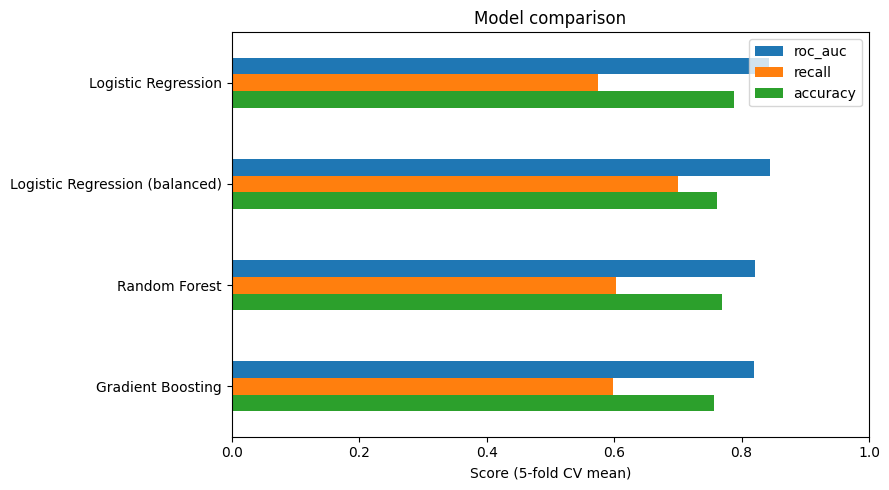

In [8]:
import matplotlib.pyplot as plt
ax = results_df[["roc_auc", "recall", "accuracy"]].plot(kind="barh", figsize=(9, 5))
ax.set_xlim(0, 1)
ax.set_xlabel("Score (5-fold CV mean)")
ax.set_ylabel("")
ax.set_title("Model comparison")
ax.invert_yaxis()
plt.tight_layout()
plt.show()